In [ ]:
# Paths: set DATA_DIR / OUTPUT_DIR as environment variables, or edit the defaults below.
import os
DATA_DIR = os.environ.get("DATA_DIR", "../data")


In [14]:
import pandas as pd
import numpy as np
import joblib
import lightgbm as lgb
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.metrics import mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import os

In [15]:
pass  # Colab only: from google.colab import drive
pass  # Colab only: drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [16]:
BASE_DIR     = DATA_DIR + "/"
DATASETS_DIR = BASE_DIR + "datasets/"
MODELS_DIR   = BASE_DIR + "models/"
REGIONS_DIR  = BASE_DIR + "regions/"
NATIONAL_DIR = BASE_DIR + "national/"
FIGURES_DIR  = BASE_DIR + "figures/"

In [17]:
#Loading national grid and collision data
national_grid = pd.read_csv(NATIONAL_DIR + "national_grid_history.csv")
collisions    = pd.read_csv(DATASETS_DIR + "collisions_features.csv",
                            dtype={'collision_index': str}, low_memory=False)
collisions['datetime'] = pd.to_datetime(collisions['datetime'])
print(f"National grid: {len(national_grid):,} grid cells")
print(f"Collisions:    {len(collisions):,}")

National grid: 43,903 grid cells
Collisions:    503,407


In [18]:
#Attaching grid history to every collision
collisions['grid_lat'] = collisions['latitude'].round(2)
collisions['grid_lon'] = collisions['longitude'].round(2)
collisions['grid_id']  = (collisions['grid_lat'].astype(str) + '_' +
                           collisions['grid_lon'].astype(str))

df = collisions.merge(
    national_grid[['grid_id','base_risk_score','log_freq','serious_rate',
                    'hist_freq_score','hist_severity_score',
                    'pct_dark','pct_wet','pct_rural','pct_high_speed']],
    on='grid_id', how='left'
)

# Filling unmatched grid cells with national medians
for col in ['base_risk_score','log_freq','serious_rate',
            'hist_freq_score','hist_severity_score',
            'pct_dark','pct_wet','pct_rural','pct_high_speed']:
    df[col] = df[col].fillna(national_grid[col].median())

print(f"Matched collisions: {df['base_risk_score'].notna().sum():,}")

Matched collisions: 503,407


In [19]:
#Encoding categoricals
le_time    = LabelEncoder()
le_season  = LabelEncoder()
le_surface = LabelEncoder()
df['time_bucket_enc'] = le_time.fit_transform(df['time_bucket'])
df['season_enc']      = le_season.fit_transform(df['season'])
df['surface_enc']     = le_surface.fit_transform(df['surface_label'])

In [20]:
#target
df['target_risk'] = (
    0.6 * df['log_freq'] / df['log_freq'].max() +
    0.4 * df['is_serious'].astype(float)
)

In [21]:
#feature matrix
feature_cols = [
    'hour','day_of_week','month','time_bucket_enc','season_enc',
    'is_weekend','is_rush_hour','friday_evening',
    'is_dark','is_dark_no_lights','light_conditions',
    'is_wet_road','is_icy_road','is_bad_weather',
    'surface_enc','weather_conditions',
    'speed_limit','road_type','urban_or_rural_area',
    'is_dual_carriageway','is_high_speed','is_rural_road',
    'at_junction','junction_detail',
    'dark_and_wet','high_speed_and_dark','high_speed_and_wet',
    'rural_and_dark','dark_and_no_lights',
    'base_risk_score','log_freq','serious_rate',
    'hist_freq_score','hist_severity_score',
    'pct_dark','pct_wet','pct_rural','pct_high_speed',
]

X = df[feature_cols].fillna(0)
y = df['target_risk']

In [22]:
#train/test split
train_mask = df['datetime'].dt.year <= 2022
test_mask  = df['datetime'].dt.year >= 2023
X_train, y_train = X[train_mask], y[train_mask]
X_test,  y_test  = X[test_mask],  y[test_mask]
print(f"Train: {len(X_train):,} | Test: {len(X_test):,}")

Train: 298,237 | Test: 205,170


In [23]:
#model training (LightGBM)
model = lgb.LGBMRegressor(
    n_estimators      = 1000,
    learning_rate     = 0.02,
    max_depth         = 6,
    num_leaves        = 31,
    min_child_samples = 20,
    subsample         = 0.8,
    colsample_bytree  = 0.8,
    reg_alpha         = 0.1,
    reg_lambda        = 0.1,
    random_state      = 42,
    verbose           = -1
)

model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    callbacks=[lgb.early_stopping(50, verbose=False),
               lgb.log_evaluation(200)]
)

[200]	valid_0's l2: 0.0264516
[400]	valid_0's l2: 0.0262991
[600]	valid_0's l2: 0.0262642
[800]	valid_0's l2: 0.0262307


LGBMRegressor(colsample_bytree=0.8, learning_rate=0.02, max_depth=6,
              n_estimators=1000, random_state=42, reg_alpha=0.1, reg_lambda=0.1,
              subsample=0.8, verbose=-1)

In [24]:
#Evaluation
y_pred = model.predict(X_test)
mae    = mean_absolute_error(y_test, y_pred)
r2     = r2_score(y_test, y_pred)
print(f"\nNational Model Performance")
print(f"MAE:  {mae:.4f}")
print(f"R²:   {r2:.4f}  (Manchester baseline was 0.3508)")
print(f"Predicted range: {y_pred.min():.3f} → {y_pred.max():.3f}")
print(f"Actual range:    {y_test.min():.3f} → {y_test.max():.3f}")


National Model Performance
MAE:  0.1281
R²:   0.4100  (Manchester baseline was 0.3508)
Predicted range: 0.005 → 0.717
Actual range:    0.023 → 1.000



Top 15 Features
            feature  importance
       serious_rate        4613
    base_risk_score        3279
               hour        2133
           log_freq        2100
            pct_wet        1522
           pct_dark        1371
     pct_high_speed        1081
        speed_limit        1054
          road_type        1034
              month         989
        day_of_week         980
hist_severity_score         956
 weather_conditions         843
    junction_detail         817
          pct_rural         600


<Figure size 1000x800 with 0 Axes>

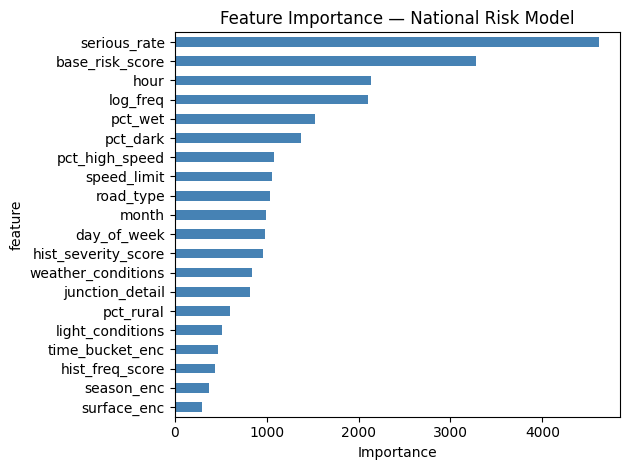

In [25]:
#Feature importance
importance = pd.DataFrame({
    'feature':    feature_cols,
    'importance': model.feature_importances_
}).sort_values('importance', ascending=False)

print(f"\nTop 15 Features")
print(importance.head(15).to_string(index=False))

plt.figure(figsize=(10, 8))
importance.head(20).plot(kind='barh', x='feature', y='importance',
                          legend=False, color='steelblue')
plt.title('Feature Importance — National Risk Model')
plt.xlabel('Importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(FIGURES_DIR + 'feature_importance_national.png', dpi=150)
plt.show()

In [26]:
#Save
joblib.dump(model,      MODELS_DIR + 'risk_model_v3_national.pkl')
joblib.dump(le_time,    MODELS_DIR + 'le_time_v3.pkl')
joblib.dump(le_season,  MODELS_DIR + 'le_season_v3.pkl')
joblib.dump(le_surface, MODELS_DIR + 'le_surface_v3.pkl')
print("\n National model saved as risk_model_v3_national.pkl")


 National model saved as risk_model_v3_national.pkl
